# Load libraries and packages

In [1]:
import ee
import os
import xee
import geemap
import folium
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import hvplot.xarray  # noqa
from tqdm.notebook import tqdm
import h5netcdf
import netCDF4
import h5py
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from scipy.stats import f_oneway
from datetime import datetime
from matplotlib.backends.backend_pdf import PdfPages
import math
from matplotlib.colors import ListedColormap, BoundaryNorm

# Load data, examine, reorder and recode NAs (255s)

In [2]:
SID = 'SID_0e404fbd-9cd0-4d12-bf5c-c71e0c144deb'

file_path = fr'C:\Users\ohlle\OneDrive\Dokumente\TUM\Master\Research Practice\data\nc\SID_0e404fbd-9cd0-4d12-bf5c-c71e0c144deb.nc'

print(file_path)

C:\Users\ohlle\OneDrive\Dokumente\TUM\Master\Research Practice\data\nc\SID_0e404fbd-9cd0-4d12-bf5c-c71e0c144deb.nc


In [3]:
df = xr.open_dataset(file_path)

In [4]:
print(df)

<xarray.Dataset> Size: 298MB
Dimensions:                    (time: 453, y: 256, x: 256)
Coordinates:
  * time                       (time) datetime64[ns] 4kB 2013-04-15T03:23:26....
  * y                          (y) float64 2kB 6.31e+05 6.311e+05 ... 6.387e+05
  * x                          (x) float64 2kB 2.746e+05 2.747e+05 ... 2.823e+05
    cubo:distance_from_center  (y, x) float64 524kB ...
    spatial_ref                int64 8B ...
Data variables:
    blue                       (time, y, x) uint16 59MB ...
    green                      (time, y, x) uint16 59MB ...
    red                        (time, y, x) uint16 59MB ...
    lwir                       (time, y, x) uint16 59MB ...
    qa_pixel                   (time, y, x) uint16 59MB ...
    geomorphic                 (y, x) uint8 66kB ...
    benthic                    (y, x) uint8 66kB ...
    reef_mask                  (y, x) uint8 66kB ...
Attributes:
    stac:                 https://earthengine-stac.storage.googleapis.

In [5]:
df = df.sortby('time')
print(df.time.values[:5])   # first 5 timestamps
print(df.time.values[-5:])  # last 5 timestamps

['2000-04-03T03:14:05.878000000' '2000-09-26T03:12:03.598000000'
 '2001-04-22T03:11:42.792000000' '2001-05-08T03:11:37.988000000'
 '2001-05-24T03:11:27.172000000']
['2024-09-28T03:21:29.566000000' '2024-10-22T03:21:41.827000000'
 '2024-10-30T03:21:44.962000000' '2024-11-07T03:21:38.222000000'
 '2024-11-15T03:21:41.526000000']


In [6]:
NaNs = df.isnull().sum()
print("NaN counts per variable:")
print(NaNs)

NaN counts per variable:
<xarray.Dataset> Size: 72B
Dimensions:      ()
Coordinates:
    spatial_ref  int64 8B ...
Data variables:
    blue         int64 8B 0
    green        int64 8B 0
    red          int64 8B 0
    lwir         int64 8B 0
    qa_pixel     int64 8B 0
    geomorphic   int64 8B 0
    benthic      int64 8B 0
    reef_mask    int64 8B 0
Attributes:
    stac:                 https://earthengine-stac.storage.googleapis.com/cat...
    epsg:                 32648
    resolution:           30
    edge_size:            256
    edge_size_m:          7680
    central_lat:          5.740194
    central_lon:          102.999556
    central_y:            634872.1063149344
    central_x:            278465.03227322665
    time_coverage_start:  2000-01-01
    time_coverage_end:    2024-12-31


In [7]:
# If benthic has no time dimension:
benthic_data = df['benthic'].values

# If benthic has a time dimension, select one slice:
# benthic_data = df['benthic'].isel(time=0).values

# Get unique values and their counts
unique_vals, counts = np.unique(benthic_data, return_counts=True)

# Combine into a dict or just print
for val, count in zip(unique_vals, counts):
    print(f"Value {val}: {count} pixels")

Value 11: 1079 pixels
Value 12: 130 pixels
Value 13: 512 pixels
Value 14: 63 pixels
Value 15: 1248 pixels
Value 255: 62504 pixels


In [8]:
# change benthic unmapped pixels back to 0 from 255
df['benthic'] = df['benthic'].where(df['benthic'] != 255, 0)

# If benthic has no time dimension:
benthic_data = df['benthic'].values

# If benthic has a time dimension, select one slice:
# benthic_data = df['benthic'].isel(time=0).values

# Get unique values and their counts
unique_vals, counts = np.unique(benthic_data, return_counts=True)

# Combine into a dict or just print
for val, count in zip(unique_vals, counts):
    print(f"Value {val}: {count} pixels")

Value 0: 62504 pixels
Value 11: 1079 pixels
Value 12: 130 pixels
Value 13: 512 pixels
Value 14: 63 pixels
Value 15: 1248 pixels


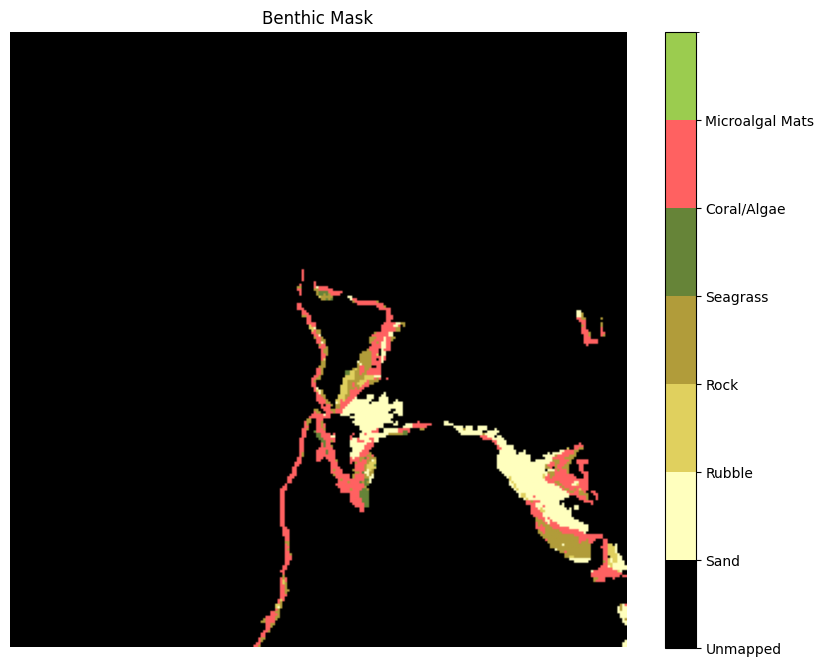

In [9]:
# Assuming df is already loaded and is your xarray.Dataset
benthic = df['benthic']

# Create the color map
color_dict = {
    0: "#000000",    # Unmapped
    11: "#ffffbe",   # Sand
    12: "#e0d05e",   # Rubble
    13: "#b19c3a",   # Rock
    14: "#668438",   # Seagrass
    15: "#ff6161",   # Coral/Algae
    18: "#9bcc4f"    # Microalgal Mats
}

# Create a list of all possible values in order
classes = list(color_dict.keys())
colors = [color_dict[k] for k in classes]

# Set up the colormap and normalization
cmap = ListedColormap(colors)
norm = BoundaryNorm(classes + [max(classes) + 1], cmap.N)

# Plot the data (selecting a time slice if needed)
plt.figure(figsize=(10, 8))
im = plt.imshow(benthic.values, cmap=cmap, norm=norm)
plt.title("Benthic Mask")
cbar = plt.colorbar(im, ticks=classes)
cbar.ax.set_yticklabels([
    "Unmapped", "Sand", "Rubble", "Rock", "Seagrass", "Coral/Algae", "Microalgal Mats"
])
plt.axis('off')
# Save plot to the requested output folder
output_dir = r"C:\Users\ohlle\OneDrive\Dokumente\TUM\Master\Research Practice\nc_analysis"
os.makedirs(output_dir, exist_ok=True)
plt.savefig(os.path.join(output_dir, f"{SID}_benthic_mask.pdf"), bbox_inches='tight')
plt.show()

# Compute percentiles across channels for ALL pixels and clip each time slice to increase image contrast while maintaining hue.

In [10]:
# Step 1: Define global shared clipping range from all RGB pixels
def global_clip(df, pmin, pmax):
    r = df.red.values.flatten()
    g = df.green.values.flatten()
    b = df.blue.values.flatten()
    stacked = np.concatenate([r[~np.isnan(r)], g[~np.isnan(g)], b[~np.isnan(b)]])
    return np.percentile(stacked, [pmin, pmax])

In [11]:
#Step: Define plotting function

def plot_slice(df, time_index, clip_min, clip_max, ax=None):
    red = df.red.isel(time=time_index)
    green = df.green.isel(time=time_index)
    blue = df.blue.isel(time=time_index)

    # Normalize using global clip range
    def normalize(band):
        return ((band - clip_min).clip(0, clip_max - clip_min)) / (clip_max - clip_min)

    red_norm = normalize(red)
    green_norm = normalize(green)
    blue_norm = normalize(blue)

    # Stack RGB
    rgb = xr.concat([red_norm, green_norm, blue_norm], dim='band')
    rgb = rgb.assign_coords(band=['red', 'green', 'blue'])
    rgb = rgb.transpose('y', 'x', 'band')
    rgb_np = np.nan_to_num(rgb.values, nan=0.0)

    # Plot to given axis or default
    if ax is None:
        ax = plt.gca()
    
    ax.imshow(rgb_np)
    ax.set_title(pd.to_datetime(df.time.values[time_index]).date(), fontsize=8)
    ax.axis('off')

In [12]:
#Step3: Apply global clip and plot functions into tiled pdf
clip_min, clip_max = global_clip(df, pmin=15, pmax=96)
num_images = len(df.time)
tiles_per_page = 96
rows, cols = 12, 8
num_pages = math.ceil(num_images / tiles_per_page)

############################################################## added
# increase resolution and avoid interpolation blur
plt.rcParams['figure.dpi'] = 200
plt.rcParams['savefig.dpi'] = 200
plt.rcParams['image.interpolation'] = 'nearest'

# force larger figure size for the tiled pages (override figsize passed to plt.subplots)
_orig_subplots = plt.subplots
def _subplots(*args, **kwargs):
    kwargs['figsize'] = (24, 24)
    fig, axes = _orig_subplots(*args, **kwargs)
    fig.set_dpi(200)
    return fig, axes
plt.subplots = _subplots
#####################################################


with PdfPages(os.path.join(output_dir, f"{SID}_all_rgb.pdf")) as pdf: 
    for page in tqdm(range(num_pages), desc="Creating PDF pages"):
        fig, axes = plt.subplots(rows, cols, figsize=(12, 12))
        axes = axes.flatten()

        for i in range(tiles_per_page):
            time_idx = page * tiles_per_page + i
            if time_idx >= num_images:
                axes[i].axis('off')
                continue
            plot_slice(df, time_index=time_idx, clip_min=clip_min, clip_max=clip_max, ax=axes[i])

        plt.tight_layout()
        pdf.savefig(fig)
        plt.close(fig)

Creating PDF pages:   0%|          | 0/5 [00:00<?, ?it/s]

In [13]:
print(f"Global shared clip range: {clip_min:.1f} – {clip_max:.1f}")

Global shared clip range: 5704.0 – 65535.0


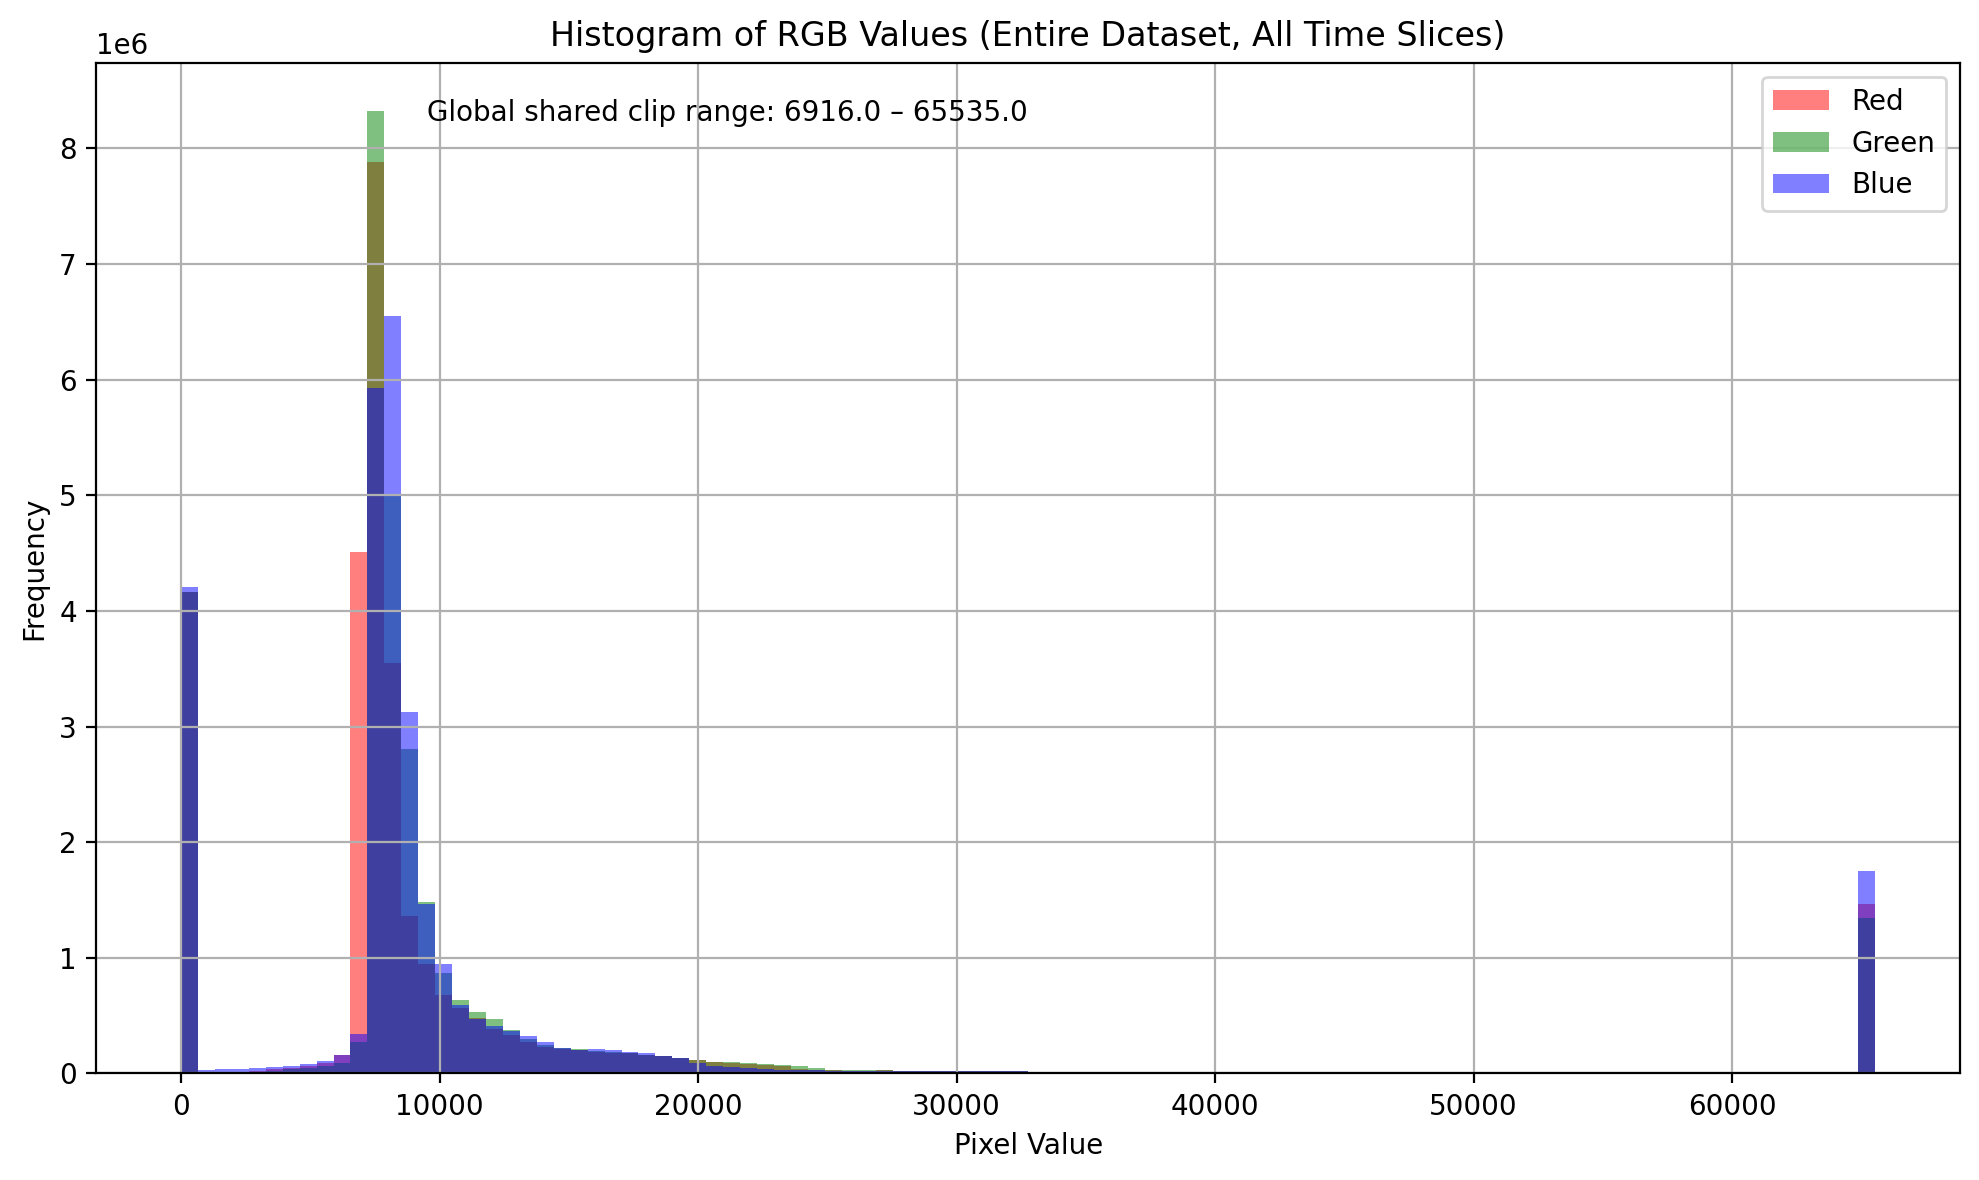

In [21]:
# Extract values across all time slices
red_vals = df.red.values
green_vals = df.green.values
blue_vals = df.blue.values

# Flatten and remove NaNs
r = red_vals[~np.isnan(red_vals)].flatten()
g = green_vals[~np.isnan(green_vals)].flatten()
b = blue_vals[~np.isnan(blue_vals)].flatten()

# Plot histograms
plt.figure(figsize=(10, 6))
plt.hist(r, bins=100, color='red', alpha=0.5, label='Red')
plt.hist(g, bins=100, color='green', alpha=0.5, label='Green')
plt.hist(b, bins=100, color='blue', alpha=0.5, label='Blue')

# Add clip range text to plot (adjust x/y as needed)
clip_text = f"Global shared clip range: {clip_min:.1f} – {clip_max:.1f}"
plt.text(0.5, 0.95, clip_text, fontsize=10, ha='right', va='center', transform=plt.gca().transAxes)

plt.xlabel('Pixel Value')
plt.ylabel('Frequency')
plt.title('Histogram of RGB Values (Entire Dataset, All Time Slices)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, f"{SID}_all_histogram.pdf"), bbox_inches='tight')
plt.show()

# Compute percentiles across channels for CORAL pixels and clip each time slice to increase image contrast while maintaining hue.

In [15]:
# Step 1: Compute shared clipping range using only benthic == 15 pixels
def global_clip_benthic15(df, pmin, pmax):
    mask = df.benthic == 15

    r = df.red.where(mask).values.flatten()
    g = df.green.where(mask).values.flatten()
    b = df.blue.where(mask).values.flatten()

    stacked = np.concatenate([
        r[~np.isnan(r)],
        g[~np.isnan(g)],
        b[~np.isnan(b)]
    ])
    
    return np.percentile(stacked, [pmin, pmax])

In [16]:
# Step 2: Plot one time slice using the benthic==15 mask and shared clip range
def plot_slice_benthic15(df, time_index, clip_min, clip_max, ax=None):
    mask = df.benthic == 15

    red = df.red.isel(time=time_index).where(mask)
    green = df.green.isel(time=time_index).where(mask)
    blue = df.blue.isel(time=time_index).where(mask)

    def normalize(band):
        return ((band - clip_min).clip(0, clip_max - clip_min)) / (clip_max - clip_min)

    red_norm = normalize(red)
    green_norm = normalize(green)
    blue_norm = normalize(blue)

    rgb = xr.concat([red_norm, green_norm, blue_norm], dim='band')
    rgb = rgb.assign_coords(band=['red', 'green', 'blue'])
    rgb = rgb.transpose('y', 'x', 'band')
    rgb_np = np.nan_to_num(rgb.values, nan=0.0)

  # Plot to given axis or default
    if ax is None:
        ax = plt.gca()
    
    ax.imshow(rgb_np)
    ax.set_title(pd.to_datetime(df.time.values[time_index]).date(), fontsize=8)
    ax.axis('off')

In [17]:
#Step3: Apply global clip and plot functions into tiled pdf
clip_min, clip_max = global_clip_benthic15(df, pmin=15, pmax=96)
num_images = len(df.time)
tiles_per_page = 96
rows, cols = 12, 8
num_pages = math.ceil(num_images / tiles_per_page)

with PdfPages(os.path.join(output_dir, f"{SID}_coral_rgb.pdf")) as pdf:
    for page in tqdm(range(num_pages), desc="Creating PDF pages"):
        fig, axes = plt.subplots(rows, cols, figsize=(12, 12))
        axes = axes.flatten()

        for i in range(tiles_per_page):
            time_idx = page * tiles_per_page + i
            if time_idx >= num_images:
                axes[i].axis('off')
                continue
            plot_slice_benthic15(df, time_index=time_idx, clip_min=clip_min, clip_max=clip_max, ax=axes[i])

        plt.tight_layout()
        pdf.savefig(fig)
        plt.close(fig)

Creating PDF pages:   0%|          | 0/5 [00:00<?, ?it/s]

In [18]:
print(f"Shared clip range (benthic=15): {clip_min:.1f} – {clip_max:.1f}")

Shared clip range (benthic=15): 6916.0 – 65535.0


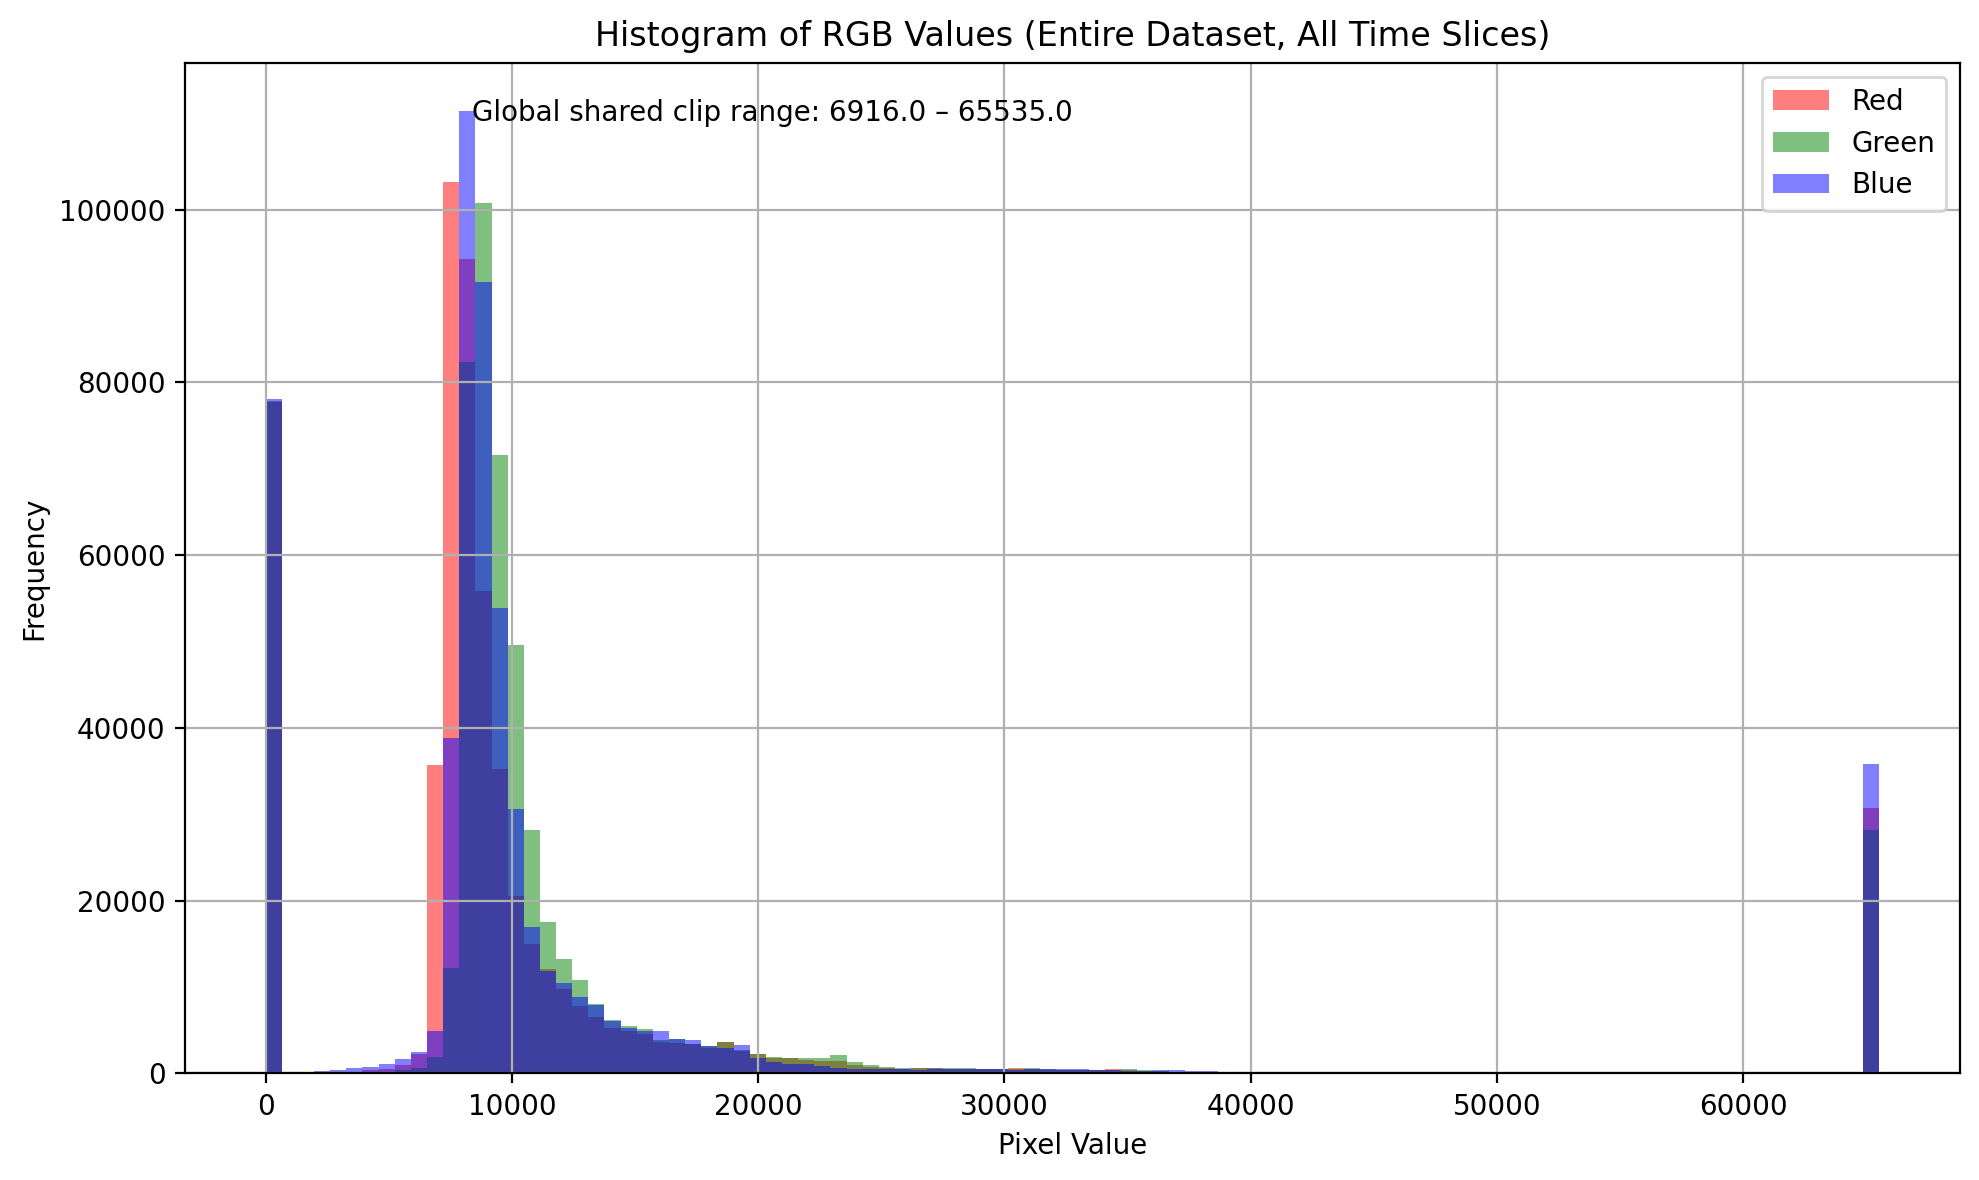

In [20]:
# Extract values across all time slices
mask = df.benthic == 15

r = df.red.where(mask).values.flatten()
g = df.green.where(mask).values.flatten()
b = df.blue.where(mask).values.flatten()

stacked = np.concatenate([
    r[~np.isnan(r)],
    g[~np.isnan(g)],
    b[~np.isnan(b)]
])

# Plot histograms
plt.figure(figsize=(10, 6))
plt.hist(r, bins=100, color='red', alpha=0.5, label='Red')
plt.hist(g, bins=100, color='green', alpha=0.5, label='Green')
plt.hist(b, bins=100, color='blue', alpha=0.5, label='Blue')

# Add clip range text to plot (adjust x/y as needed)
clip_text = f"Global shared clip range: {clip_min:.1f} – {clip_max:.1f}"
plt.text(0.5, 0.95, clip_text, fontsize=10, ha='right', va='center', transform=plt.gca().transAxes)

plt.xlabel('Pixel Value')
plt.ylabel('Frequency')
plt.title('Histogram of RGB Values (Entire Dataset, All Time Slices)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, f"{SID}_coral_histogram.pdf"), bbox_inches='tight')
plt.show()

In [22]:
plt.figure(figsize=(15, 8))

# Create the boxplot
plt.boxplot(data_for_boxplot2, labels=[str(t)[:10] for t in df['time'].values])


# Add titles and labels
plt.title('Boxplot of SR_B3 Across Time')
plt.xlabel('Time')
plt.ylabel('SR_B3 Values')

# Rotate x-axis labels for better readability
plt.xticks(rotation=90)

# Show the plot
plt.tight_layout()
plt.show()

NameError: name 'data_for_boxplot2' is not defined

<Figure size 3000x1600 with 0 Axes>

In [23]:
time_labels = [pd.to_datetime(str(t)).strftime('%Y-%m') for t in df['time'].values]

In [24]:
plt.figure(figsize=(15, 8))

# Create the boxplot
plt.boxplot(data_for_boxplot, labels=time_labels)

# Add titles and labels
plt.title('Boxplot of SR_B1 Across Time')
plt.xlabel('Time (Month-Year)')
plt.ylabel('SR_B1 Values')

# Rotate x-axis labels for better readability
plt.xticks(rotation=90)

# Show the plot
plt.tight_layout()
plt.show()

NameError: name 'data_for_boxplot' is not defined

<Figure size 3000x1600 with 0 Axes>

In [25]:
times = pd.to_datetime(df['time'].values)
time_labels = times.strftime('%Y-%m')
years = times.year

In [26]:
norm = mcolors.Normalize(vmin=years.min(), vmax=years.max())
cmap = cm.coolwarm # You can choose any colormap you like

In [27]:
plt.figure(figsize=(15, 8))

# Create the boxplot
plt.boxplot(data_for_boxplot, labels=time_labels)

# Add titles and labels
plt.title('Boxplot of SR_B1 Across Time')
plt.xlabel('Time (Month-Year)')
plt.ylabel('SR_B1 Values')

# Rotate x-axis labels for better readability and color them by year
ax = plt.gca()
previous_year = years[0]
year_positions = []
for i, (tick_label, year) in enumerate(zip(ax.get_xticklabels(), years)):
    tick_label.set_rotation(90)
    tick_label.set_color(cmap(norm(year)))
    if year != previous_year:
        ax.axvline(i + 0.5, color='grey', linestyle='--', linewidth=0.5)
        year_positions.append((i + 0.5, previous_year))
        previous_year = year
year_positions.append((len(years) - 0.5, previous_year))

# Add year labels at the top
for pos, year in year_positions:
    ax.text(pos -1.5, ax.get_ylim()[1], str(year), va='bottom', ha='center', fontsize=10, color='black')

# Show the plot
plt.tight_layout()
plt.show()

NameError: name 'data_for_boxplot' is not defined

<Figure size 3000x1600 with 0 Axes>